# Figure 1 C–D — state-space manifold and structure index of d2

Both use the 10 window features of the non-overlapping 30 s windows, z-scored per session; d2 (2024 Euclidean) is a label, not a feature.

Each panel is saved to `../figure_output/<Fig>/`.

In [1]:
# Data: ../csv/Fig1_CD_manifold_structure_index/
from pathlib import Path
import pandas as pd
CSV = Path('..') / 'csv' / 'Fig1_CD_manifold_structure_index'


def read_csv(name, **kw):
    """A table of this notebook (round_trip: the floats exactly as written)."""
    return pd.read_csv(CSV / name, float_precision='round_trip', **kw)

import os, sys
sys.path.insert(0, os.path.abspath('.'))   # figure_scripts/
import final_figs as F                     # print styles, saving, stars

## Fig 1C — state-space manifold (UMAP)

- Drawn by `fig1_state_umap_all18.ipynb` from the saved embedding of `fig1_state_space_umap_session.py` (`SESSION=all FSET=10`): 10 window features z-scored per session, non-overlapping 30 s windows each inside one state, UMAP (Euclidean, n_neighbors 20, random_state 42); d2 shown z-scored within session.
- Windows: NREM 6 042, Wake non-θ 2 632, REM 227, Wake θ 231 (9 132 windows, 18 sessions, 6 mice).

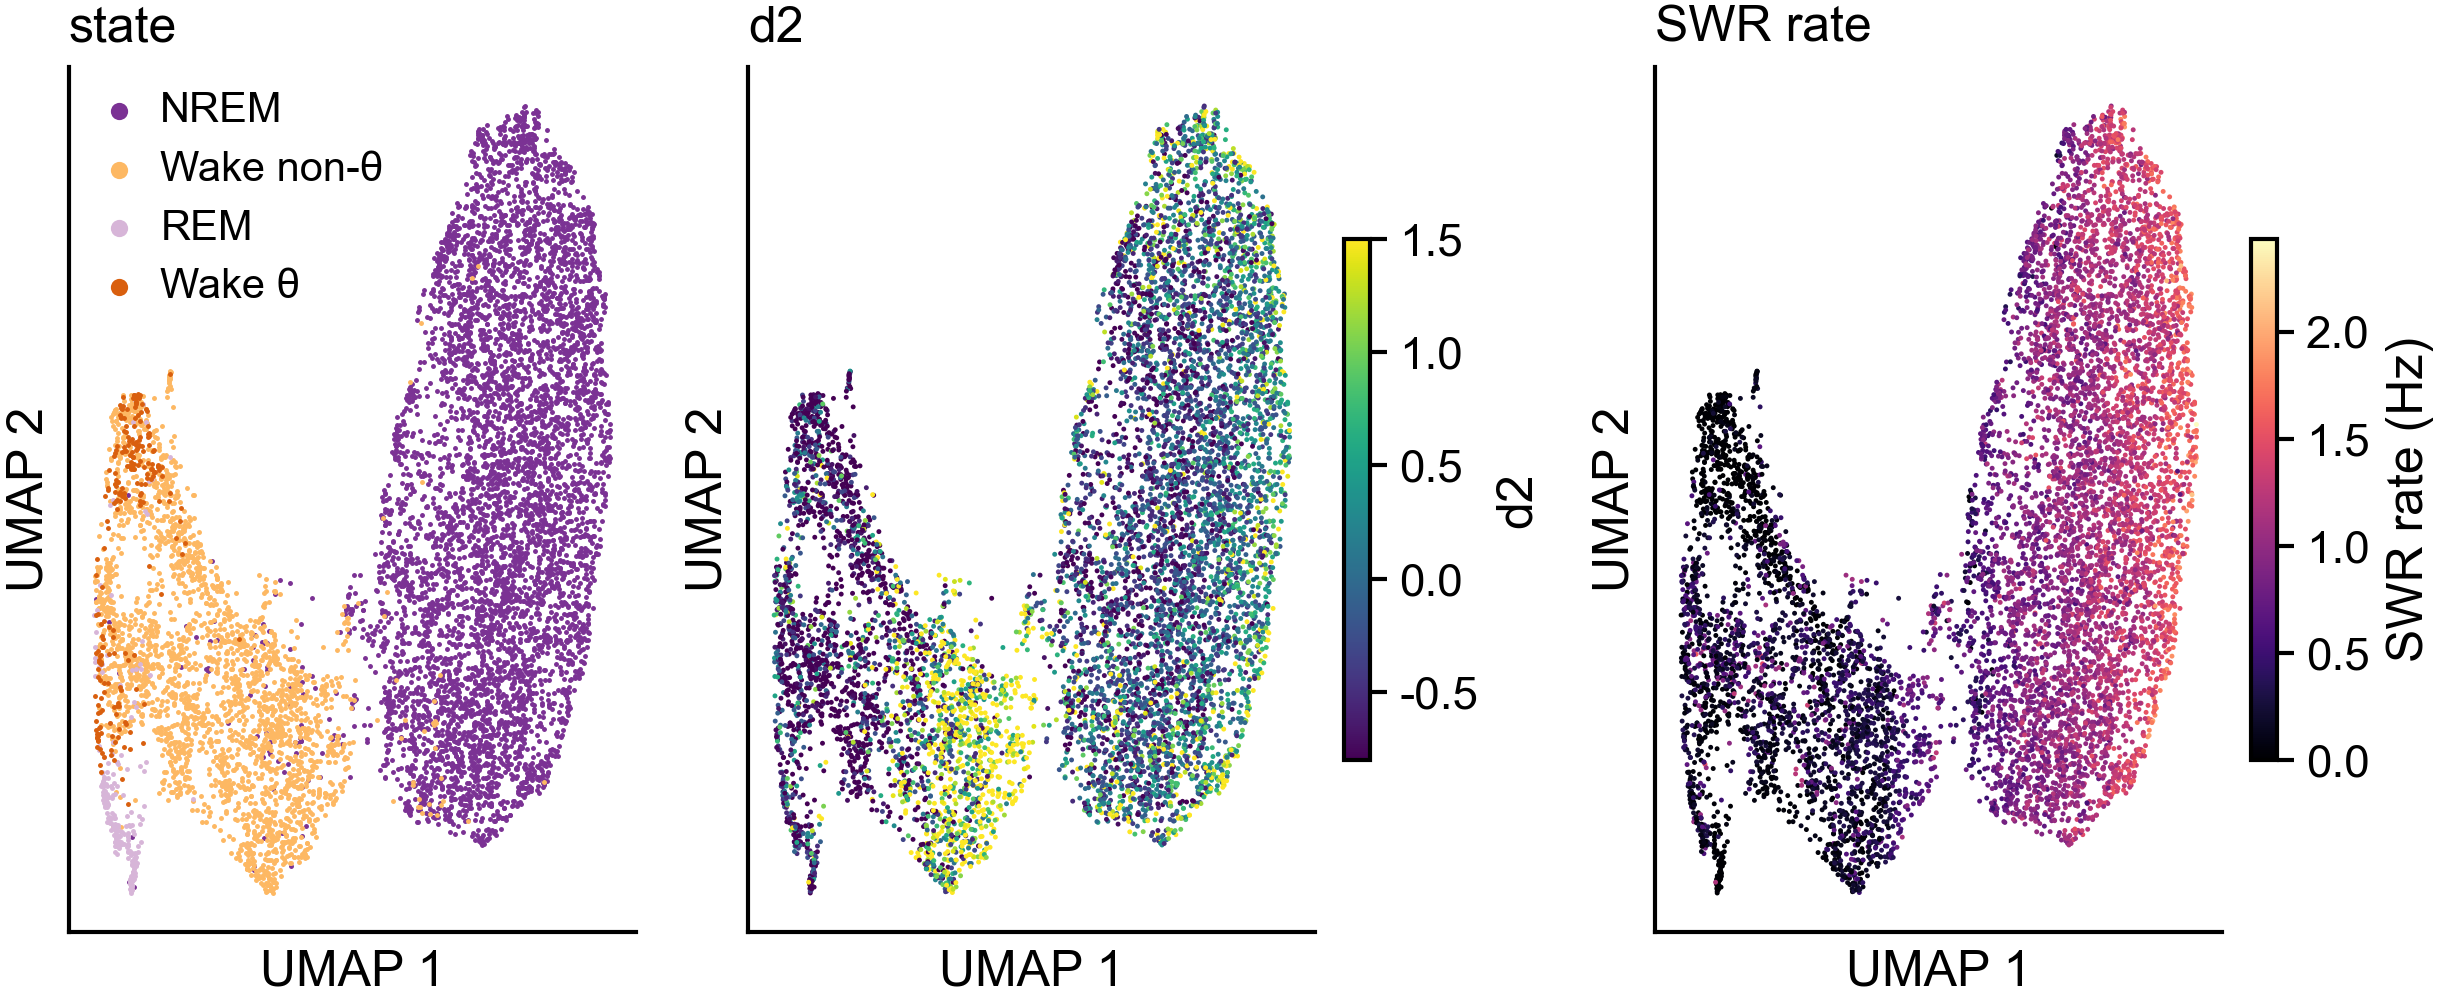

In [2]:
# ---- data (../csv) ----
SRC_NB = "fig1_state_umap_all18.ipynb"   # its copy, beside this notebook
# ---- the same from the recordings, with analysis_scripts/: ----
# SRC_NB = os.path.join(F.REV, "fig1_state_umap_all18.ipynb")
W_MM, H_MM = 105, 44                                # final size of the panel
OVERRIDES = f"""# final-size settings, inserted by Fig1_CD_manifold_structure_index.ipynb (the notebook is run in memory)
sys.path.insert(0, {os.path.dirname(os.path.abspath(F.__file__))!r})
import final_figs as F
F.final_style(6)
FIGSIZE = ({W_MM} * F.MM, {H_MM} * F.MM)
POINT_SIZE = 0.35
FONT_SIZE, TITLE_SIZE = 6, 6
LEGEND_FONTSIZE, LEGEND_MARKERSCALE = 5, 3.5
LEGEND_LOC = "upper left"
PANEL_LETTERS = SHOW_SUPTITLE = SHOW_FOOTNOTE = False
SHOW_TEST = False                                    # the per-session test is panel D
COMPUTE_SI = False                                   # no pooled-SI line in the titles
OUT = F.stem("Fig1_C_manifold")
DPI = 600
"""
REPLACE = [('label="d2 (2024 Euclidean), z within session"', 'label="d2"'),  # d2 (2024 Euclidean)
           ('title = "SWR rate (also a feature)"', 'title = "SWR rate"'),
           ('label="SWR rate (Hz, per 30 s window)"', 'label="SWR rate (Hz)"'),
           # legend without window counts; constrained layout
           ('label=f"{STATE_LABEL[st]} ({len(g)})")', 'label=STATE_LABEL[st])'),
           ("figsize=FIGSIZE, squeeze=False)", 'figsize=FIGSIZE, squeeze=False, layout="constrained")'),
           ("fig.tight_layout()", "pass  # constrained layout")]
F.run_nb(SRC_NB, after_cell=3, overrides=OVERRIDES, replace=REPLACE)
F.show(F.stem("Fig1_C_manifold") + ".png")

## Fig 1D — structure index of d2 per session vs its own null

- Structure index (PridaLab) of d2 (2024 Euclidean, 40 ms, AR p = 20) in the 10-D z-scored window-feature space, all states, 10 bins, n_neighbors 20; null = d2 circularly shifted within each state episode, 500 surrogates.
- 18 sessions, 9 132 windows; each session's SI against its own null 95th percentile, paired Wilcoxon signed-rank test.
- Producer: `notebooks/exploration/revision/fig1_si_sessions.py` → `fig1_si_sessions.csv`.

d: SI above its own time-shifted null in 18 of 18 sessions; two-sided Wilcoxon signed-rank p = 7.6e-06; n = 18 sessions from 6 mice


saved figure_output\Fig1\Fig1_D_structure_index.svg / .png


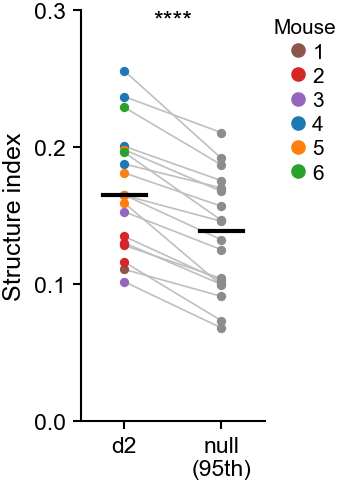

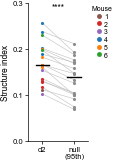

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
# ---- data (../csv) ----
import fig1_si_sessions_drawing as SI_   # fig1_si_sessions.py's mouse colours and labels (copied)
R = pd.read_csv(CSV / 'fig1_si_sessions.csv')   # fig1_si_sessions.py's table (data/revision/log)
# ---- the same from the recordings, with analysis_scripts/: ----
# import fig1_si_sessions as SI_
# 
# REPLOT_SOURCE = False                     # True: also redraw the producer's own (exploration-size) figure
# if REPLOT_SOURCE:
#     import subprocess
#     subprocess.run([sys.executable, os.path.join(F.REV, "fig1_si_sessions.py")],
#                    env={**os.environ, "PLOT_ONLY": "1"}, check=True)
# R = pd.read_csv(SI_.OUT)                  # data/revision/log/fig1_si_sessions.csv
d = (R.SI - R.null_p95).to_numpy()
p = stats.wilcoxon(d).pvalue
print(f"d: SI above its own time-shifted null in {int((d > 0).sum())} of {len(R)} sessions; two-sided Wilcoxon "
      f"signed-rank p = {p:.2g}; n = {len(R)} sessions from {R.animal.nunique()} mice")

F.final_style()
fig, ax = plt.subplots(figsize=(31 * F.MM, 42.5 * F.MM), constrained_layout=True)
animals = sorted(R.animal.unique(), key=lambda a: int(a[3:]))
for _, r in R.iterrows():                 # the producer's plot(), at final size
    ax.plot([0, 1], [r.SI, r.null_p95], color="0.75", lw=0.4, zorder=1)
    ax.scatter(0, r.SI, s=5, color=SI_.MOUSE_COL[r.animal], zorder=3, lw=0)
    ax.scatter(1, r.null_p95, s=5, color="0.55", zorder=3, lw=0)
for x, col in ((0, "SI"), (1, "null_p95")):
    ax.plot([x - 0.22, x + 0.22], [R[col].median()] * 2, color="k", lw=1.0, zorder=4)
top = 0.30
ax.text(0.5, top, f"{int((d > 0).sum())}/{len(R)} sessions\n{F.stars(p)}", ha="center", va="top", fontsize=6)   # stars: four significance levels
ax.set_xticks([0, 1]); ax.set_xticklabels(["d2", "null\n(95th)"]); ax.set_xlim(-0.45, 1.45)
ax.set_ylim(0, top); ax.set_yticks([0, 0.1, 0.2, 0.3]); ax.set_ylabel("Structure index")
h = [plt.Line2D([], [], marker="o", ms=2.5, ls="", color=SI_.MOUSE_COL[a], label=SI_.MOUSE_LABEL[a].replace("Mouse ", ""))
     for a in animals]
ax.legend(handles=h, title="Mouse", title_fontsize=5, fontsize=5, ncol=1, loc="upper left", bbox_to_anchor=(1.0, 1.0),
          handletextpad=0.1, borderaxespad=0, labelspacing=0.25)
F.settle(fig)
F.drop_counts(fig)                          # formal panel: no k/n; counts in the legend
png = F.save(fig, "Fig1_D_structure_index")
F.show(png)